# 1. Inventory Optimization Environment Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

DATA_DIR = Path("../data/processed")
RAW_DIR = Path("../data/raw/m5")
MODELS_DIR = Path("../models")

print("Inventory Optimization Environment Ready!")

Inventory Optimization Environment Ready!


# 2. Loading Historical Products Sales Data

In [2]:
sales_df = pd.read_csv(
    RAW_DIR / "sales_train_validation.csv"
)

print("Dataset Shape:", sales_df.shape)
print("\nFirst 5 Rows:")
display(sales_df.head())

Dataset Shape: (30490, 1919)

First 5 Rows:


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


# 3. Product-Level Demand Analysis

In [3]:
daily_cols = [
    col for col in sales_df.columns
    if col.startswith("d_")
]

demand_stats = sales_df[
    ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
].copy()

demand_stats["total_sales"] = sales_df[daily_cols].sum(axis=1)

demand_stats["avg_daily_demand"] = (
    sales_df[daily_cols].mean(axis=1)
)

demand_stats["demand_std"] = (
    sales_df[daily_cols].std(axis=1)
)

demand_stats["non_zero_days"] = (
    (sales_df[daily_cols] > 0).sum(axis=1)
)

print("Demand Statistics Shape:", demand_stats.shape)
display(demand_stats.head())

Demand Statistics Shape: (30490, 10)


,id,item_id,dept_id,cat_id,store_id,state_id,total_sales,avg_daily_demand,demand_std,non_zero_days
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,600,0.313643,0.685250,421
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,493,0.257710,0.569422,402
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,288,0.150549,0.486557,216
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,3288,1.718766,1.989867,1296
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,1849,0.966545,1.294472,963


# 4. Inventory Planning Assumptions

In [4]:
LEAD_TIME_DAYS = 7
SERVICE_LEVEL_Z = 1.65
REVIEW_PERIOD_DAYS = 7

print("Inventory Planning Assumptions")
print("--------------------------------")
print("Lead Time:", LEAD_TIME_DAYS, "days")
print("Service Level Z:", SERVICE_LEVEL_Z)
print("Review Period:", REVIEW_PERIOD_DAYS, "days")

Inventory Planning Assumptions
--------------------------------
Lead Time: 7 days
Service Level Z: 1.65
Review Period: 7 days


These are illustrative assumptions, not actual Walmart supplier data.

# 5. Safety Stock and Reorder Point Calculation

In [5]:
demand_stats["safety_stock"] = (
    SERVICE_LEVEL_Z
    * demand_stats["demand_std"]
    * np.sqrt(LEAD_TIME_DAYS)
)

demand_stats["reorder_point"] = (
    demand_stats["avg_daily_demand"] * LEAD_TIME_DAYS
    + demand_stats["safety_stock"]
)

demand_stats["reorder_point"] = np.ceil(
    demand_stats["reorder_point"]
).astype(int)

demand_stats["safety_stock"] = np.ceil(
    demand_stats["safety_stock"]
).astype(int)

print("Safety Stock and Reorder Point Calculated!")

display(
    demand_stats[
        ["item_id", "store_id", "avg_daily_demand",
         "demand_std", "safety_stock", "reorder_point"]
    ].head(10)
)

Safety Stock and Reorder Point Calculated!


,item_id,store_id,avg_daily_demand,demand_std,safety_stock,reorder_point
0,HOBBIES_1_001,CA_1,0.313643,0.685250,3,6
1,HOBBIES_1_002,CA_1,0.257710,0.569422,3,5
2,HOBBIES_1_003,CA_1,0.150549,0.486557,3,4
3,HOBBIES_1_004,CA_1,1.718766,1.989867,9,21
4,HOBBIES_1_005,CA_1,0.966545,1.294472,6,13
5,HOBBIES_1_006,CA_1,0.858338,1.571951,7,13
6,HOBBIES_1_007,CA_1,0.221641,0.504179,3,4
7,HOBBIES_1_008,CA_1,7.229482,9.116295,40,91
8,HOBBIES_1_009,CA_1,1.186095,2.015078,9,18
9,HOBBIES_1_010,CA_1,0.719289,0.921687,5,10


Simple meaning:
- Safety Stock = Extra stock kept as a buffer.
- Reorder Point = Stock level at which replenishment should be triggered.
These are preliminary estimates using a normal-demand approximation. Intermittent-demand products may need a more specialized method later.

One observation: products with higher demand variability generally require more safety stock. For example, HOBBIES_1_008 has a safety stock of 40 units, compared with 3 units for HOBBIES_1_001.

# 6. Target Stock Level Calculation
The target stock level represents a simulated replenishment target, not actual Walmart inventory.

In [6]:
demand_stats["target_stock"] = (
    demand_stats["avg_daily_demand"]
    * (LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS)
    + demand_stats["safety_stock"]
)

demand_stats["target_stock"] = np.ceil(
    demand_stats["target_stock"]
).astype(int)

print("Target Stock Levels Calculated!")

display(
    demand_stats[
        ["item_id", "store_id", "safety_stock",
         "reorder_point", "target_stock"]
    ].head(10)
)

Target Stock Levels Calculated!


,item_id,store_id,safety_stock,reorder_point,target_stock
0,HOBBIES_1_001,CA_1,3,6,8
1,HOBBIES_1_002,CA_1,3,5,7
2,HOBBIES_1_003,CA_1,3,4,6
3,HOBBIES_1_004,CA_1,9,21,34
4,HOBBIES_1_005,CA_1,6,13,20
5,HOBBIES_1_006,CA_1,7,13,20
6,HOBBIES_1_007,CA_1,3,4,7
7,HOBBIES_1_008,CA_1,40,91,142
8,HOBBIES_1_009,CA_1,9,18,26
9,HOBBIES_1_010,CA_1,5,10,16


Now we need one more thing: current stock availability.

The M5 dataset doesn't contain actual inventory quantities, so we'll create a clearly labelled simulated inventory scenario to demonstrate replenishment decisions.

# 7. Simulated Inventory Availability

In [7]:
rng = np.random.default_rng(42)

demand_stats["simulated_on_hand_stock"] = np.floor(
    demand_stats["target_stock"]
    * rng.uniform(0.3, 1.5, size=len(demand_stats))
).astype(int)

print("Simulated Inventory Generated!")

display(
    demand_stats[
        ["item_id", "store_id", "target_stock",
         "simulated_on_hand_stock"]
    ].head(10)
)

Simulated Inventory Generated!


,item_id,store_id,target_stock,simulated_on_hand_stock
0,HOBBIES_1_001,CA_1,8,9
1,HOBBIES_1_002,CA_1,7,5
2,HOBBIES_1_003,CA_1,6,7
3,HOBBIES_1_004,CA_1,34,38
4,HOBBIES_1_005,CA_1,20,8
5,HOBBIES_1_006,CA_1,20,29
6,HOBBIES_1_007,CA_1,7,8
7,HOBBIES_1_008,CA_1,142,176
8,HOBBIES_1_009,CA_1,26,11
9,HOBBIES_1_010,CA_1,16,13


# 8. Inventory Replenishment Recommendations
What this does:
- If current stock is at or below the reorder point → Reorder.
- If stock is above the reorder point → Sufficient.
- Order quantity = Target stock − Current stock.
These recommendations are based on our simulated inventory scenario.

In [8]:
demand_stats["replenishment_status"] = np.where(
    demand_stats["simulated_on_hand_stock"]
    <= demand_stats["reorder_point"],
    "Reorder",
    "Sufficient"
)

demand_stats["recommended_order_qty"] = np.where(
    demand_stats["replenishment_status"] == "Reorder",
    np.maximum(
        demand_stats["target_stock"]
        - demand_stats["simulated_on_hand_stock"],
        0
    ),
    0
)

print("Replenishment Recommendations Generated!")

display(
    demand_stats[
        ["item_id", "store_id",
         "simulated_on_hand_stock",
         "reorder_point", "target_stock",
         "replenishment_status",
         "recommended_order_qty"]
    ].head(15)
)

Replenishment Recommendations Generated!


,item_id,store_id,simulated_on_hand_stock,reorder_point,target_stock,replenishment_status,recommended_order_qty
0,HOBBIES_1_001,CA_1,9,6,8,Sufficient,0
1,HOBBIES_1_002,CA_1,5,5,7,Reorder,2
2,HOBBIES_1_003,CA_1,7,4,6,Sufficient,0
3,HOBBIES_1_004,CA_1,38,21,34,Sufficient,0
4,HOBBIES_1_005,CA_1,8,13,20,Reorder,12
5,HOBBIES_1_006,CA_1,29,13,20,Sufficient,0
6,HOBBIES_1_007,CA_1,8,4,7,Sufficient,0
7,HOBBIES_1_008,CA_1,176,91,142,Sufficient,0
8,HOBBIES_1_009,CA_1,11,18,26,Reorder,15
9,HOBBIES_1_010,CA_1,13,10,16,Sufficient,0


# 9. Overall Replenishment Summary

In [9]:
reorder_summary = demand_stats["replenishment_status"].value_counts()

total_reorder_items = (demand_stats["replenishment_status"] == "Reorder").sum()
total_order_qty = demand_stats["recommended_order_qty"].sum()

print("INVENTORY REPLENISHMENT SUMMARY")
print("--------------------------------")
print("Total Product-Store Combinations:", len(demand_stats))
print("Items Requiring Reorder:", total_reorder_items)
print("Items With Sufficient Stock:", reorder_summary.get("Sufficient", 0))
print("Total Recommended Order Quantity:", total_order_qty)

print("\nReplenishment Status:")
display(reorder_summary)

INVENTORY REPLENISHMENT SUMMARY
--------------------------------
Total Product-Store Combinations: 30490
Items Requiring Reorder: 12472
Items With Sufficient Stock: 18018
Total Recommended Order Quantity: 121648

Replenishment Status:


replenishment_status
Sufficient    18018
Reorder       12472
Name: count, dtype: int64

Around 40.9% of product-store combinations need replenishment.
#
Business insight: the replenishment policy identifies where simulated stock falls below the reorder threshold. Remember, these are simulated inventory recommendations, not actual Walmart stock records.

# 10. Replanishment by Category

In [10]:
category_replenishment = (
    demand_stats.groupby("cat_id")
    .agg(
        total_items=("item_id", "count"),
        items_to_reorder=("replenishment_status",
                          lambda x: (x == "Reorder").sum()),
        total_order_qty=("recommended_order_qty", "sum")
    )
    .reset_index()
)

category_replenishment["reorder_percentage"] = (
    category_replenishment["items_to_reorder"]
    / category_replenishment["total_items"] * 100
).round(2)

display(
    category_replenishment.sort_values(
        "total_order_qty", ascending=False
    )
)

,cat_id,total_items,items_to_reorder,total_order_qty,reorder_percentage
0,FOODS,14370,5343,77009,37.18
2,HOUSEHOLD,10470,4537,29595,43.33
1,HOBBIES,5650,2592,15044,45.88


#### observations
- FOODS: Highest replenishment volume — 77,009 units, with 37.18% of combinations requiring reorder.
- HOUSEHOLD: 4,537 combinations need replenishment, with a 43.33% reorder rate.
- HOBBIES: Highest reorder percentage at 45.88%, despite having the fewest combinations.
Business insight: HOBBIES has the highest proportion of products requiring replenishment, while FOODS contributes the largest total order quantity.

Small correction: the 
output appears to have cat_id and total_items headers shifted.

# 11. Repalnishment by Stores

In [11]:
store_replenishment = (
    demand_stats.groupby("store_id")
    .agg(
        total_items=("item_id", "count"),
        items_to_reorder=("replenishment_status",
                          lambda x: (x == "Reorder").sum()),
        total_order_qty=("recommended_order_qty", "sum")
    )
    .reset_index()
)

store_replenishment["reorder_percentage"] = (
    store_replenishment["items_to_reorder"]
    / store_replenishment["total_items"] * 100
).round(2)

display(
    store_replenishment.sort_values(
        "total_order_qty", ascending=False
    )
)

,store_id,total_items,items_to_reorder,total_order_qty,reorder_percentage
2,CA_3,3049,1110,17474,36.41
0,CA_1,3049,1169,14655,38.34
5,TX_2,3049,1210,14542,39.69
6,TX_3,3049,1244,11972,40.80
1,CA_2,3049,1299,11479,42.60
9,WI_3,3049,1291,11270,42.34
8,WI_2,3049,1266,11125,41.52
7,WI_1,3049,1255,10714,41.16
4,TX_1,3049,1291,9784,42.34
3,CA_4,3049,1337,8633,43.85


#### Key business insights
- CA_3: Highest recommended order quantity — 17,474 units, with the lowest reorder percentage (36.41%).
- CA_4: Highest reorder percentage — 43.85%, but the lowest recommended order quantity (8,633 units).
- CA_1: Second-highest order quantity — 14,655 units.
- TX_2: 39.69% of its product-store combinations require replenishment.
#### Important distinction: A higher reorder percentage doesn't necessarily mean a higher order quantity. Demand volume and stock requirements also matter.

# 12. Visualize Replanishment by Catepgory

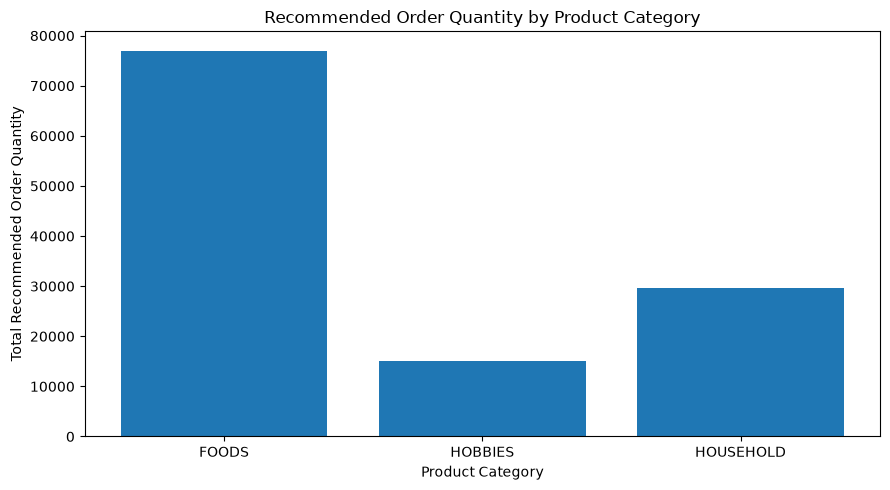

In [12]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_replenishment["cat_id"],
    category_replenishment["total_order_qty"]
)

plt.title("Recommended Order Quantity by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Recommended Order Quantity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 12. Top 15 Products Requiring Replenishment

In [13]:
top_replenishment_items = (
    demand_stats[
        demand_stats["recommended_order_qty"] > 0
    ]
    .sort_values(
        "recommended_order_qty",
        ascending=False
    )
    [
        [
            "item_id",
            "store_id",
            "avg_daily_demand",
            "simulated_on_hand_stock",
            "reorder_point",
            "target_stock",
            "recommended_order_qty"
        ]
    ]
    .head(15)
)

display(top_replenishment_items)

,item_id,store_id,avg_daily_demand,simulated_on_hand_stock,reorder_point,target_stock,recommended_order_qty
18055,FOODS_3_586,TX_2,100.802405,808,841,1547,739
20608,FOODS_3_090,TX_3,60.038683,398,631,1051,653
17721,FOODS_3_252,TX_2,59.672243,325,522,940,615
2810,FOODS_3_586,CA_1,45.839519,252,393,714,462
23793,FOODS_3_226,WI_1,41.292734,193,353,643,450
20770,FOODS_3_252,TX_3,45.285938,285,407,725,440
9003,FOODS_3_681,CA_3,29.031364,173,312,516,343
2476,FOODS_3_252,CA_1,39.190277,297,357,631,334
30378,FOODS_3_714,WI_3,28.622582,171,262,463,292
2937,FOODS_3_714,CA_1,28.269733,185,262,460,275


### What we discovered
- FOODS_3_586 at TX_2 has the highest recommended order quantity: 739 units.
- FOODS_3_090 at TX_3 comes second: 653 units.
- FOODS_3_252 appears across multiple stores, showing that replenishment needs can vary by store even for the same product.
### One important distinction: these are product-store combinations, not unique products. That's why some item IDs appear more than once.

# 13. Export Inventory Recommendations

In [14]:
inventory_output_path = DATA_DIR / "inventory_recommendations.csv"

demand_stats.to_csv(inventory_output_path, index=False)

print("Inventory recommendations saved successfully!")
print("File:", inventory_output_path)
print("Records:", len(demand_stats))

Inventory recommendations saved successfully!
File: ../data/processed/inventory_recommendations.csv
Records: 30490


# Inventory Optimization — Methodology & Limitations

## 1. Methodology

Inventory optimization was performed at the **product-store level** using historical sales data from the M5 Forecasting dataset.

The following steps were implemented:

- **Demand Statistics:** Calculated total sales, average daily demand, demand standard deviation, and non-zero sales days for each product-store combination.
- **Safety Stock:** Estimated buffer stock using demand variability and an assumed service-level factor.
- **Reorder Point:** Calculated the stock threshold at which replenishment should be triggered.
- **Target Stock:** Estimated the desired inventory level to cover the lead time and review period, along with safety stock.
- **Simulated Inventory:** Generated hypothetical on-hand inventory levels using a fixed random seed for reproducibility.
- **Replenishment Recommendations:** Compared simulated stock against reorder points and calculated recommended order quantities to reach target stock.
- **Business Analysis:** Evaluated replenishment requirements across categories, stores, and individual product-store combinations.

## 2. Key Assumptions

The following illustrative assumptions were used:

- Lead Time: 7 days
- Review Period: 7 days
- Service-Level Z-Score: 1.65 (approximately 95% one-sided service level under a normal approximation)
- Inventory levels were simulated because actual stock information was unavailable.

## 3. Limitations

1. **Simulated Inventory:** The M5 dataset does not provide actual on-hand inventory, purchase orders, backorders, or supplier lead times. Therefore, inventory levels and replenishment quantities are simulated rather than actual operational recommendations.

2. **Historical Demand:** Average demand and standard deviation were calculated using the available historical sales period. Recent changes in demand may not be fully reflected.

3. **Intermittent Demand:** Many products have irregular or zero-demand days. The normal-distribution-based safety stock calculation may not accurately represent every product's demand pattern.

4. **Simplified Inventory Policy:** The model does not account for supplier constraints, minimum order quantities, storage capacity, ordering costs, or transportation costs.

5. **Forecast Integration:** The inventory calculations use historical demand statistics rather than directly incorporating the selected XGBoost forecast. Future improvements could integrate forecasted demand into replenishment planning.

## 4. Conclusion

This inventory optimization module demonstrates how historical sales patterns can be translated into product-store-level replenishment recommendations.

Although the inventory levels and operational assumptions are simulated, the framework provides a foundation for inventory planning, stock monitoring, and replenishment decision support.

**Output File:** `data/processed/inventory_recommendations.csv`

**Total Product-Store Combinations Analyzed:** 30,490

**Total Combinations Requiring Replenishment:** 12,472

**Total Simulated Recommended Order Quantity:** 121,648 units